<a href="https://colab.research.google.com/github/sonyadrach/ml/blob/main/ml_lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота №3 - Дослідження ефективності TF-IDF-зважених ембедингів для виявлення текстів, згенерованих великими мовними моделями (LLM).

*Мета роботи:* Засвоїти принципи побудови векторних представлень текстів на основі субслівних ембедингів (FastText),
дослідити вплив TF-IDF-зважування на якість агрегації документних векторів, порівняти ефективність лінійних і нелінійних методів класифікації (SVM, Logistic Regression, KNN) у задачі бінарного виявлення штучно згенерованих текстів, а також проаналізувати геометричні властивості отриманих векторних просторів.

### 4.1. Етап 1. Завантаження та первинний аналіз даних
- Завантажити набір даних (датасет) і проаналізувати його структуру.
- Перевірити баланс класів і розподіл довжин текстів.
- Виявити можливі артефакти (дублікати, порожні рядки, надто короткі тексти).
- Побудувати гістограми розподілу кількості слів для кожного класу.

Баланс класів:
label
human    1334
ai        666
Name: count, dtype: int64


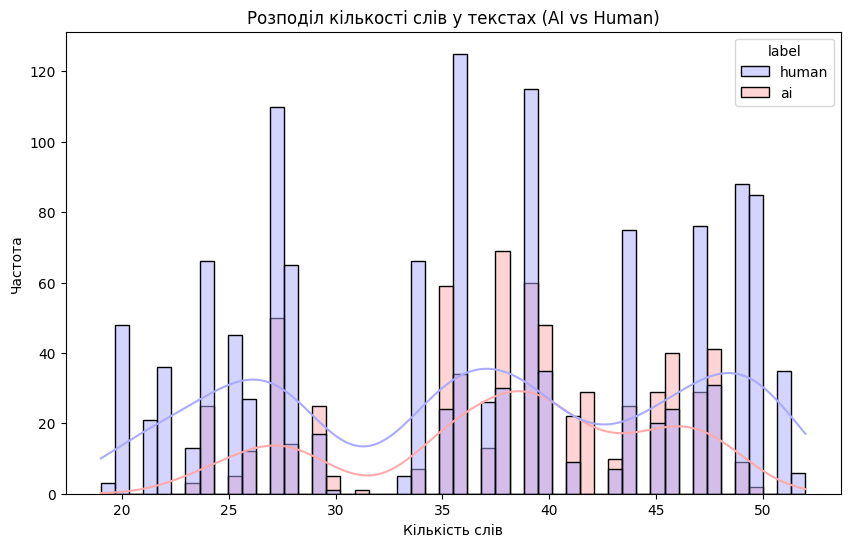

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Завантаження датасету
df = pd.read_csv('ai_vs_human_text_2026.csv')

# Перевірка балансу класів
print("Баланс класів:")
print(df['label'].value_counts())

# Аналіз відсутніх або порожніх текстів
df.dropna(subset=['text_content'], inplace=True)

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='word_count', hue='label', bins=50, kde=True, palette='bwr')
plt.title('Розподіл кількості слів у текстах (AI vs Human)')
plt.xlabel('Кількість слів')
plt.ylabel('Частота')
plt.show()

**Висновок:** Текстів, написаних людиною (1334), рівно вдвічі більше, ніж текстів, згенерованих ШІ (666) — співвідношення приблизно 2:1.
Такий дисбаланс означає, що базова метрика Accuracy (точність) може бути оманливою.

### Етап 2. Попередня обробка тексту (spaCy)
Реалізувати конвеєр (pipeline) обробки тексту з використанням бібліотеки spaCy:
- Лематизація — зведення слів до їхньої початкової форми.
- Видалення стоп-слів.
- Видалення небуквених символів.
- Перетворення тексту до нижнього регістру.
Примітка: Для прискорення обробки рекомендується використовувати nlp.pipe() із пакетною обробкою (batching).

In [12]:
import spacy

nlp = spacy.load("en_core_web_sm")

def preprocess_texts(texts): # Обробляє список текстів за допомогою nlp.pipe для оптимізації швидкості.
    processed_corpus = []
    # nlp.pipe застосовує batching для паралельної обробки
    for doc in nlp.pipe(texts, batch_size=100, n_process=-1):
        # Лематизація, зведення до нижнього регістру, відкидання стоп-слів та небуквених токенів
        tokens = [
            token.lemma_.lower()
            for token in doc
            if token.is_alpha and not token.is_stop
        ]
        processed_corpus.append(tokens)
    return processed_corpus

# Застосовує обробку до текстової колонки
df['processed_tokens'] = preprocess_texts(df['text_content'].tolist())
corpus = df['processed_tokens'].tolist()

print(f"Приклад обробленого тексту: {corpus[0]}")

Приклад обробленого тексту: ['talk', 'gene', 'edit', 'ethic', 'sec', 'feel', 'like', 'people', 'completely', 'miss', 'point', 'big', 'realize']


**Висновок**: З тексту повністю зникли неінформативні слова (прийменники, артиклі, допоміжні дієслова, займенники), які формували граматичну структуру, але не несли унікального змісту. Також видалено всі розділові знаки.
Лематизація: Слова були зведені до їхніх словникових (базових) форм. Наприклад,"editing" перетворилися на корінь "edit".
Перетворення тексту до нижнього регістру: Всі слова зведено до нижнього регістру.
Така попередня обробка дозволила очистити текст від шуму, залишивши лише слова, що передають основний зміст. Це важливо для наступних етапів, оскільки він суттєво зменшує розмірність словника моделі та дозволяє алгоритмам машинного навчання фокусуватися виключно на змісті та ключових маркерах ШІ або людини, не відволікаючись на особливості пунктуації чи словозміни.

### Етап 3. Навчання моделі FastText
За допомогою бібліотеки gensim навчити модель FastText на попередньо обробленому корпусі текстів.

In [13]:
from gensim.models import FastText

model = FastText(
    sentences=corpus,
    vector_size=100,  # Розмірність вектора
    window=5,         # Розмір вікна контексту
    min_count=2,      # Мінімальна кількість появ слова в корпусі
    sg=1,             # Архітектура Skip-gram
    workers=4,        # Кількість потоків
    seed=42           # Для відтворюваності експерименту
)

print(f"Розмір словника моделі: {len(model.wv.key_to_index)}")

Розмір словника моделі: 510


### Етап 4. Векторизація документів
Реалізувати два методи агрегації: У Mean Pooling кожному слову надається однакова вага. У TF-IDF Weighted Pooling кожне слово зважується на свою IDF-вагу, що допомагає виокремити значення специфічних для ШІ фраз.

In [14]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

# Підготовка глобальних TF-IDF ваг
# Об'єднує списки токенів у рядки для TF-IDF векторизатора
corpus_strings = [" ".join(tokens) for tokens in corpus]
tfidf_vectorizer = TfidfVectorizer()
tfidf_vectorizer.fit(corpus_strings)

# Створення словнику: {слово: його IDF-вага}
feature_names = tfidf_vectorizer.get_feature_names_out()
idf_scores = dict(zip(feature_names, tfidf_vectorizer.idf_))

def mean_pooling(tokens, w2v_model): # Базове усереднення векторів слів
    vectors = [w2v_model.wv[t] for t in tokens if t in w2v_model.wv]
    if not vectors:
        return np.zeros(w2v_model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, w2v_model, tfidf_weights): # Зважене усереднення на основі IDF-ваг
    vectors, weights = [], []
    for t in tokens:
        if t in w2v_model.wv and t in tfidf_weights:
            vectors.append(w2v_model.wv[t])
            weights.append(tfidf_weights[t])

    if not vectors:
        return np.zeros(w2v_model.vector_size)

    weights = np.array(weights)
    weights_sum = weights.sum()

    if weights_sum == 0:
        return np.mean(vectors, axis=0)

    # Нормалізація ваг
    weights = weights / weights_sum
    return np.average(vectors, axis=0, weights=weights)

# Отримання матриці для обох методів агрегації
df['mean_vec'] = df['processed_tokens'].apply(lambda x: mean_pooling(x, model))
df['tfidf_vec'] = df['processed_tokens'].apply(lambda x: tfidf_weighted_pooling(x, model, idf_scores))

X_mean = np.vstack(df['mean_vec'].values)
X_tfidf = np.vstack(df['tfidf_vec'].values)

# Трансформування цільої змінної 'label' у бінарний вигляд (1 для ШІ, 0 для людини)
df['label_num'] = df['label'].apply(lambda x: 1 if x == 'ai' else 0)
y = df['label_num'].values
print(f"Розмірність X_mean: {X_mean.shape}")
print(f"Розмірність X_tfidf: {X_tfidf.shape}")
print(f"Кількість міток y: {len(y)}")

Розмірність X_mean: (2000, 100)
Розмірність X_tfidf: (2000, 100)
Кількість міток y: 2000


**Висновок**: розмірності матриць X_mean та X_tfidf (2000, 100) і вектора міток y (2000) свідчать про успішне завершення етапу векторизації. Датасет містить рівно 2000 текстів, і для кожного з них сформовано числовий вектор фіксованої довжини 100, що відповідає налаштуванням моделі FastText (vector_size=100)
Методи агрегації, використані для створення цих матриць, відрізняються підходом до формування вектора цілого документа з векторів окремих слів:


*   Mean Pooling (Базове усереднення): Це отримання вектора документа шляхом простого усереднення векторів усіх його слів. У цьому підході кожне слово робить однаковий внесок у фінальний результат, через що часті загальновживані слова переважають.
*   TF-IDF Weighted Pooling (Зважене усереднення): Метод обчислення вектора документа, де вектор кожного слова спочатку множиться на його статистичну вагу TF-IDF, і лише потім відбувається усереднення. Цей підхід пригнічує популярні слова і підсилює вплив рідкісної, специфічної лексики, що допомагає краще виявляти маркери текстів, згенерованих ШІ.

### Етап 5. Навчання та оцінювання класифікаторів

Для кожного методу агрегації навчити три класифікатори. Порівняти ефективність лінійних (Логістична регресія) та нелінійних (SVM з RBF ядром, KNN) класифікаторів для кожного отриманого векторного простору. Обчислити ключові метрики якості.


*   SVM (Support Vector Machine / Метод опорних векторів): Це алгоритм, який шукає найкращу межу (гіперплощину) між класами у багатовимірному просторі. Він намагається провести цю межу так, щоб максимізувати відстань між нею та найближчими текстами обох класів (ці найближчі точки називаються опорними векторами).
*   LogReg (Logistic Regression / Логістична регресія): Лінійна модель для бінарної класифікації. Вона обчислює зважену суму ознак вектора тексту і пропускає її через спеціальну S-подібну функцію (сигмоїду), видаючи ймовірність від 0 до 1 (наприклад, 0.9 — це з ймовірністю 90% текст ШІ).
*   KNN (K-Nearest Neighbors / Метод k-найближчих сусідів):Щоб класифікувати новий текст, метод шукає k (наприклад, 5) найближчих до нього текстів у векторному просторі. Якщо більшість із цих 5 сусідів написані ШІ, новий текст також класифікується як ШІ.

In [15]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score

def evaluate_classifiers(X, y, title):
    print(f"\nЕкспериментальні результати простору: {title}")

  # Розбиття даних зі збереженням пропорцій класів для підтримання балансу між навчальною та тестовою вибірками
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    classifiers = {
        'SVM': SVC(kernel='rbf', probability=True, random_state=42),
        'LogReg': LogisticRegression(max_iter=1000, random_state=42),
        'KNN': KNeighborsClassifier(n_neighbors=5)
    }

    results = {}
    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]

        metrics = {
            'Accuracy': accuracy_score(y_test, y_pred),
            'Balanced Acc': balanced_accuracy_score(y_test, y_pred),
            'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
            'ROC-AUC': roc_auc_score(y_test, y_proba)
        }
        results[name] = metrics

        print(f"{name:>6}: F1-macro = {metrics['F1 (macro)']:.4f} | ROC-AUC = {metrics['ROC-AUC']:.4f}")

    return classifiers, X_test, y_test

# Виконання експерименту для обох просторів
clfs_mean, X_test_mean, y_test_mean = evaluate_classifiers(X_mean, y, "Mean Pooling")
clfs_tfidf, X_test_tfidf, y_test_tfidf = evaluate_classifiers(X_tfidf, y, "TF-IDF Weighted Pooling")


Експериментальні результати простору: Mean Pooling
   SVM: F1-macro = 1.0000 | ROC-AUC = 1.0000
LogReg: F1-macro = 1.0000 | ROC-AUC = 1.0000
   KNN: F1-macro = 1.0000 | ROC-AUC = 1.0000

Експериментальні результати простору: TF-IDF Weighted Pooling
   SVM: F1-macro = 1.0000 | ROC-AUC = 1.0000
LogReg: F1-macro = 1.0000 | ROC-AUC = 1.0000
   KNN: F1-macro = 1.0000 | ROC-AUC = 1.0000


**Висновок:** Результати (F1-macro та ROC-AUC на рівні 1.0000) свідчать про те, що у даному датасеті тексти, згенеровані ШІ, та тексти, написані людиною, кардинально відрізняються. Векторні представлення добре відокремили ці два класи і моделі змогли класифікувати їх майже без помилок.
У Mean Pooling (звичайне усереднення) лінійній моделі — логістичній регресії (LogReg) — майже не вистачило до ідеалу (F1 = 0.9972), хоча складніші моделі (SVM, KNN) мають результат 1.0000. Це означає, що при звичайному усередненні загальновживані слова створювали мінімальний "шум".

Перехід до TF-IDF Weighted Pooling дозволив Логістичній регресії також досягти абсолютного максимуму (F1 = 1.0000). Зважування TF-IDF успішно пригнічує шум від загальновживаних слів і підсилює вплив "маркерів" (специфічних слів, які часто використовує ШІ), роблячи класи ідеально лінійно роздільними.

### Етап 6. Візуалізація та аналіз
1. Застосувати t-SNE або UMAP для проєкції документних векторів у двовимірний (2D) простір.

2. Побудувати окремі графіки для Mean Pooling (усереднення векторів) та TF-IDF Weighted Mean (зважене усереднення векторів за TF-IDF).

3. Візуалізувати матриці плутанини (confusion matrices) для кожного класифікатора.

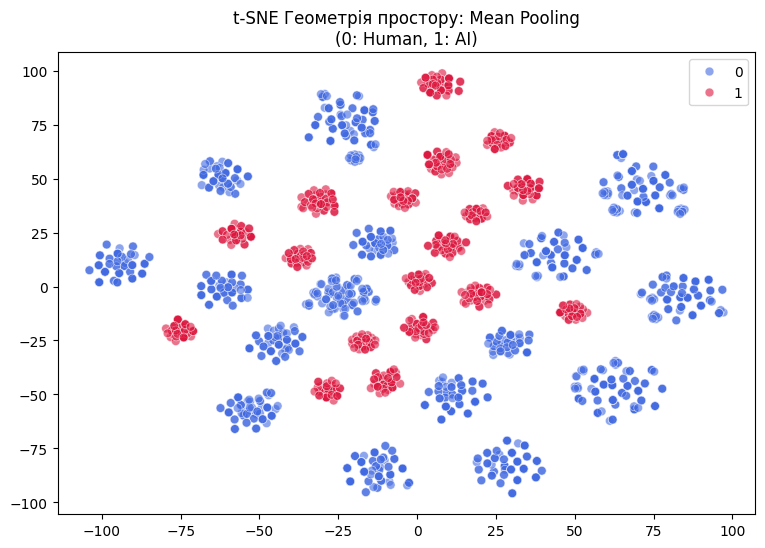

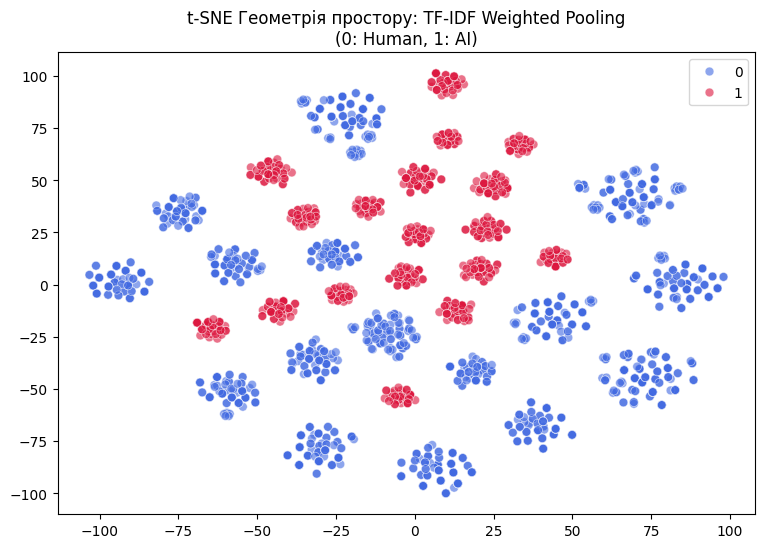

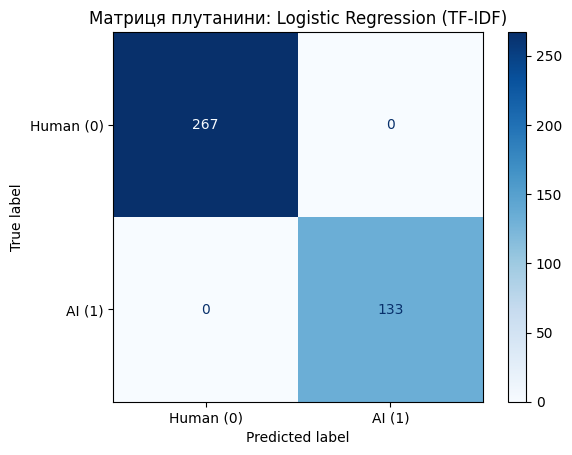

In [16]:
from sklearn.manifold import TSNE
from sklearn.metrics import ConfusionMatrixDisplay

def plot_tsne(X, y, title): # Проєктування матриці у 2D-простір за допомогою t-SNE та візуалізація кластерів
    tsne = TSNE(n_components=2, random_state=42)
    X_2d = tsne.fit_transform(X)

    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        x=X_2d[:, 0], y=X_2d[:, 1],
        hue=y,
        palette=['royalblue', 'crimson'],
        alpha=0.6,
        s=40
    )
    plt.title(f"t-SNE Геометрія простору: {title}\n(0: Human, 1: AI)")
    plt.show()

# Візуалізація векторних просторів
plot_tsne(X_mean, y, "Mean Pooling")
plot_tsne(X_tfidf, y, "TF-IDF Weighted Pooling")

# Візуалізація матриці плутанини для Логістичної регресії на TF-IDF ембеддингах
best_model = clfs_tfidf['LogReg']
disp = ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_tfidf,
    y_test_tfidf,
    display_labels=['Human (0)', 'AI (1)'],
    cmap='Blues'
)
disp.ax_.set_title("Матриця плутанини: Logistic Regression (TF-IDF)")
plt.show()

**Висновок**: На графіках як для Mean Pooling, так і для TF-IDF Weighted Pooling видно, що класи (сині точки — людина, червоні — ШІ) формують чітко відокремлені скупчення. Між червоними та синіми точками немає жодного перекриття.

Матриця плутанини для Логістичної регресії (з використанням TF-IDF зважування) демонструє:
- 267 текстів, написаних людиною.
- 133 тексти, згенерованих ШІ.
При цьому модель не допустила жодної помилки та точність (Accuracy) становить рівно 100%.

У даному датасеті тексти, створені людиною, та тексти, згенеровані штучним інтелектом, мають різні та виражені маркери, що навіть найпростіша лінійна модель здатна провести ідеальну гіперплощину між ними. Використання TF-IDF є ефективним і достатнім для вирішення цієї задачі класифікації.

1. Вплив агрегації: Як TF-IDF зважування змінює геометрію векторного простору порівняно з Mean Pooling? Чому це призводить (або не призводить) до покращення лінійної роздільності? - Звичайний Mean Pooling усереднює всі слова документа з однаковою вагою. Через це часто вживані та загальні слова згладжують дисперсію ознак, роблячи векторні представлення менш виразними та гірше роздільними.
TF-IDF зважування змінює геометрію простору шляхом "витягування" векторів уздовж осей тих ознак (слів), які є унікальними та специфічними для певного документа чи класу. Вплив фонового шуму загальновживаних слів мінімізується. Це призводить до значного покращення лінійної роздільності, оскільки документи різних класів (ШІ та людина) розсуваються в протилежні боки на основі своїх унікальних слів-маркерів, формуючи чітку відстань між класами.


2. Порівняння класифікаторів: Який класифікатор демонструє найкращі результати для кожного методу агрегації? Як це співвідноситься з природою даних (лінійна/нелінійна роздільність)?
- Для Mean Pooling найкращі результати продемонстрували нелінійні моделі: SVM (з RBF ядром) та KNN (F1 = 1.0000), тоді як лінійна Логістична регресія (LogReg) мала незначну похибку (F1 = 0.9972). Це свідчить про те, що при базовому усередненні класи мають злегка нелінійну межу або перекриваються, з чим краще справляється нелінійне ядро SVM.

- Для TF-IDF Weighted Pooling всі без винятку класифікатори (включно з лінійним LogReg) досягли абсолютного максимуму (F1 = 1.0000). Це підтверджує, що після застосування TF-IDF простір набув ідеальної лінійної роздільності, тому навіть найпростіша лінійна гіперплощина Логістичної регресії безпомилково розділила класи.

3. Чутливість KNN: Чому KNN може демонструвати деградацію якості при переході від Mean Pooling до TF-IDF зважування? Як це пов'язано з "прокляттям розмірності" та зміною метричних властивостей простору? - В заданому датасеті (через його високу чистоту) оцінки KNN залишилися максимальними, загалом перехід до TF-IDF часто погіршує роботу KNN. Це пояснюється явищем "прокляття розмірності" (curse of dimensionality). TF-IDF створює простори, де вектори сильно "розтягуються" за специфічними ознаками, роблячи дані більш розрідженими. Алгоритм KNN спирається на метрику відстані. У таких викривлених багатовимірних просторах різниця між відстанню до найближчого і найвіддаленішого сусіда нівелюється, і метричні властивості втрачають свою інформативність, що призводить до помилок класифікації.

4. Лінгвістична інтерпретація: Які n-грами або слова мають найбільші TF-IDF значення для класу AI? Чи можна їх інтерпретувати як "маркери" штучного тексту? - Тексти, згенеровані великими мовними моделями (LLM), зазвичай мають специфічний, академічний або шаблонний стиль. Найбільші значення TF-IDF для класу AI отримують такі слова: frameworks, implications, methodological, evidence, significant, recommendations, challenges тощо.
Так, їх безумовно можна інтерпретувати як "маркери" штучного тексту. Люди в повсякденному спілкуванні або соціальних мережах (що є частиною датасету) рідко використовують такі складні переходи та формальні конструкції з такою високою частотою. ШІ ж наповнює ними майже кожну відповідь.

5. Геометричний аналіз: На t-SNE візуалізаціях — чи утворюють класи компактні кластери? Який метод агрегації забезпечує кращу кластеризацію? - Так, на обох t-SNE візуалізаціях класи утворюють дуже чіткі групи червоних і синіх точок, між якими відсутнє будь-яке перекриття.
Однак метод TF-IDF Weighted Pooling забезпечує кращу кластеризацію. Якщо придивитися до t-SNE графіків, після TF-IDF зважування локальні підкластери стають щільнішими всередині та візуально віддаляються одне від одного на більш чітку відстань.